# GP vs flat length scale (ZOIB linking): log Bayes factor and coherence fields

A simpler version of `study9-gp-vs-flat-zoib.ipynb`. Two models of the Study 9 ratings, differing only in
whether coherence generalization is distance-based:

- **fitted**: `length_scale` fitted -> `results/study9-fit-zoib/posterior.npz`
- **flat** (distance-blind null): `length_scale = LS_FLAT = 10` -> `results/study9-fit-zoib/posterior-null.npz`

Both use the per-feature ZOIB linking, profiled at each model's own θ.

In [1]:
DATA_CSV = '../../data/study9_prereg.csv'

import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys
sys.path.insert(0, ".")

import json
import numpy as np
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()
import inference as inf

RESULTS = os.path.join('results', 'study9-fit-zoib')
MODEL_SPECS = {'fitted': 'posterior.npz', 'flat': 'posterior-null.npz'}

def _load(fname):
    z = np.load(os.path.join(RESULTS, fname), allow_pickle=True)
    meta = json.loads(str(z['meta']))
    return {'ls':    float(np.median(z['ls_samples'])),
            'mu_0':  float(np.median(z['mu0_samples'])),
            'sigma': float(np.median(z['sigma_samples'])),
            'beta':  float(np.median(z['beta_samples'])),
            'elbo':  float(meta['elbo']),
            'elbo_sd': meta.get('elbo_sd'),          # only saved by fits run after it was added
            'status': meta['convergence_status'],
            'file':  fname}

MODELS = {name: _load(f) for name, f in MODEL_SPECS.items()}
assert MODELS['flat']['ls'] == inf.LS_FLAT, "flat model should have ls pinned at LS_FLAT"

geom = inf.load_geometry()
J = geom['J']
responses_cond, _ = inf.load_responses(DATA_CSV, clip_interior=False)    # RAW ratings for the ZOIB
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in inf.CONDITIONS}
N_cond   = {c: int(responses_cond[c].shape[0]) for c in inf.CONDITIONS}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

## 1. log Z per model and the log Bayes factor

**log Z (VBMC ELBO).** For each model, the ELBO from its VBMC run: a lower bound on (and estimate of) the
log marginal likelihood `log p(data | model) = log ∫ p(data | θ) p(θ) dθ`, integrating over the GP
hyperparameters θ under their priors (the linking is profiled at each θ). Because θ is integrated out,
it already penalizes the fitted model's extra parameter (`ls`); no AIC/BIC correction is needed.

**log Bayes factor** = `log Z_fitted − log Z_flat` (> 0 favours the fitted length scale). In natural-log
units, Kass & Raftery (1995): < 1.1 barely worth mentioning, 1.1–3 positive, 3–5 strong, > 5 very strong
(BF thresholds 3, 20, 150). Jeffreys (1961), BF thresholds 10^0.5, 10, 10^1.5, 100, i.e. ln BF 1.15 / 2.3 /
3.45 / 4.6: substantial / strong / very strong / decisive. If the runs saved `elbo_sd`, the BF's
SD is `sqrt(sd_fitted² + sd_flat²)` (VBMC's estimate of its own ELBO noise).

For reference, the plug-in Laplace `log Z` at each model's posterior-median θ is shown too: it is
`log p(data | θ̂)` with θ fixed, so it does **not** pay for the extra parameter.

In [2]:
plugin = {}
for name, m in MODELS.items():
    plugin[name] = inf.total_log_lik_zoib(geom, responses_cond, m['ls'], m['mu_0'], m['sigma'],
                                          beta_speaker=m['beta'])

print(f"{'model':<8}{'ls':>8}{'mu_0':>8}{'sigma':>8}{'beta':>8}{'log Z (ELBO)':>15}{'ELBO sd':>9}"
      f"{'plug-in log Z':>15}  status")
for name, m in MODELS.items():
    sd = f"{m['elbo_sd']:.2f}" if m['elbo_sd'] is not None else 'n/a'
    print(f"{name:<8}{m['ls']:>8.3g}{m['mu_0']:>+8.3f}{m['sigma']:>8.3f}{m['beta']:>8.2f}"
          f"{m['elbo']:>15.2f}{sd:>9}{float(plugin[name]):>15.2f}  {m['status']}")

log_bf = MODELS['fitted']['elbo'] - MODELS['flat']['elbo']
sds = [MODELS[n]['elbo_sd'] for n in MODELS]
bf_sd = None if None in sds else float(np.hypot(*sds))
print(f"\nlog BF (fitted vs flat)   = {log_bf:+.2f}" + (f"  ± {bf_sd:.2f}" if bf_sd is not None else
      "   (ELBO sd not saved for these runs; refit to get it)"))
print(f"BF                        = {np.exp(log_bf):.3g}")
print(f"plug-in log LR (no Occam) = {float(plugin['fitted']) - float(plugin['flat']):+.2f}")

model         ls    mu_0   sigma    beta   log Z (ELBO)  ELBO sd  plug-in log Z  status
fitted     0.344  +1.293   0.522   25.93       -1724.91      n/a       -1719.89  probable
flat          10  +1.480   0.429   22.80       -1731.77      n/a       -1726.59  probable

log BF (fitted vs flat)   = +6.86   (ELBO sd not saved for these runs; refit to get it)
BF                        = 954
plug-in log LR (no Occam) = +6.70


## 2. Coherence fields: one color scale, shared across models

One row per model, one column per condition. The background is the GP coherence field `P(kind-linked)`
at the model's posterior-median θ. **Both rows use the same coherence range** (the min/max over every
panel of both models), so the flat model's field shows up as what it is: one uniform shade per condition,
with no structure across the embedding, while the fitted model's varies with distance from the trained
features (stars).

Test features (circles) are filled by their empirical mean prevalence rating with the **same colormap**,
but on the ratings' own range. The single colorbar carries both scales: coherence on the **left**,
mean prevalence rating on the **right**. So the colors line up in *ordering* (darker = higher on each
scale); the two scales are different quantities, and the numbers are read off their own side.

In [3]:
all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in inf.CONDITIONS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 80), np.linspace(y_lo, y_hi, 80))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test_np = np.array(geom['x_test'])

fields, field_at_test = {}, {}
for name, m in MODELS.items():
    for c in inf.CONDITIONS:
        fields[name, c] = inf.gp_coherence_field(geom, c, m['ls'], m['mu_0'], m['sigma'],
                                                 X_grid, beta_speaker=m['beta']).reshape(gx.shape)
        field_at_test[name, c] = inf.gp_coherence_field(geom, c, m['ls'], m['mu_0'], m['sigma'],
                                                        x_test_np, beta_speaker=m['beta'])

f_all = np.stack(list(fields.values()))
COH_LO, COH_HI = float(f_all.min()), float(f_all.max())      # shared by BOTH models
RAT_LO = min(e.min() for e in emp_cond.values())
RAT_HI = max(e.max() for e in emp_cond.values())
LEVELS = np.linspace(COH_LO, COH_HI, 21)
CMAP = 'Blues'
print(f"coherence range (both models): [{COH_LO:.3f}, {COH_HI:.3f}]")
print(f"mean-rating range:             [{RAT_LO:.3f}, {RAT_HI:.3f}]")
for name in MODELS:
    spread = [np.ptp(fields[name, c]) for c in inf.CONDITIONS]
    print(f"  {name:<7} within-condition field spread: " + ", ".join(f"{s:.4f}" for s in spread))

coherence range (both models): [0.787, 0.845]
mean-rating range:             [0.352, 0.766]
  fitted  within-condition field spread: 0.0555, 0.0586, 0.0532, 0.0419
  flat    within-condition field spread: 0.0001, 0.0001, 0.0001, 0.0001


saved results/study9-fit-zoib/coherence-field-fig-shared-scale.png


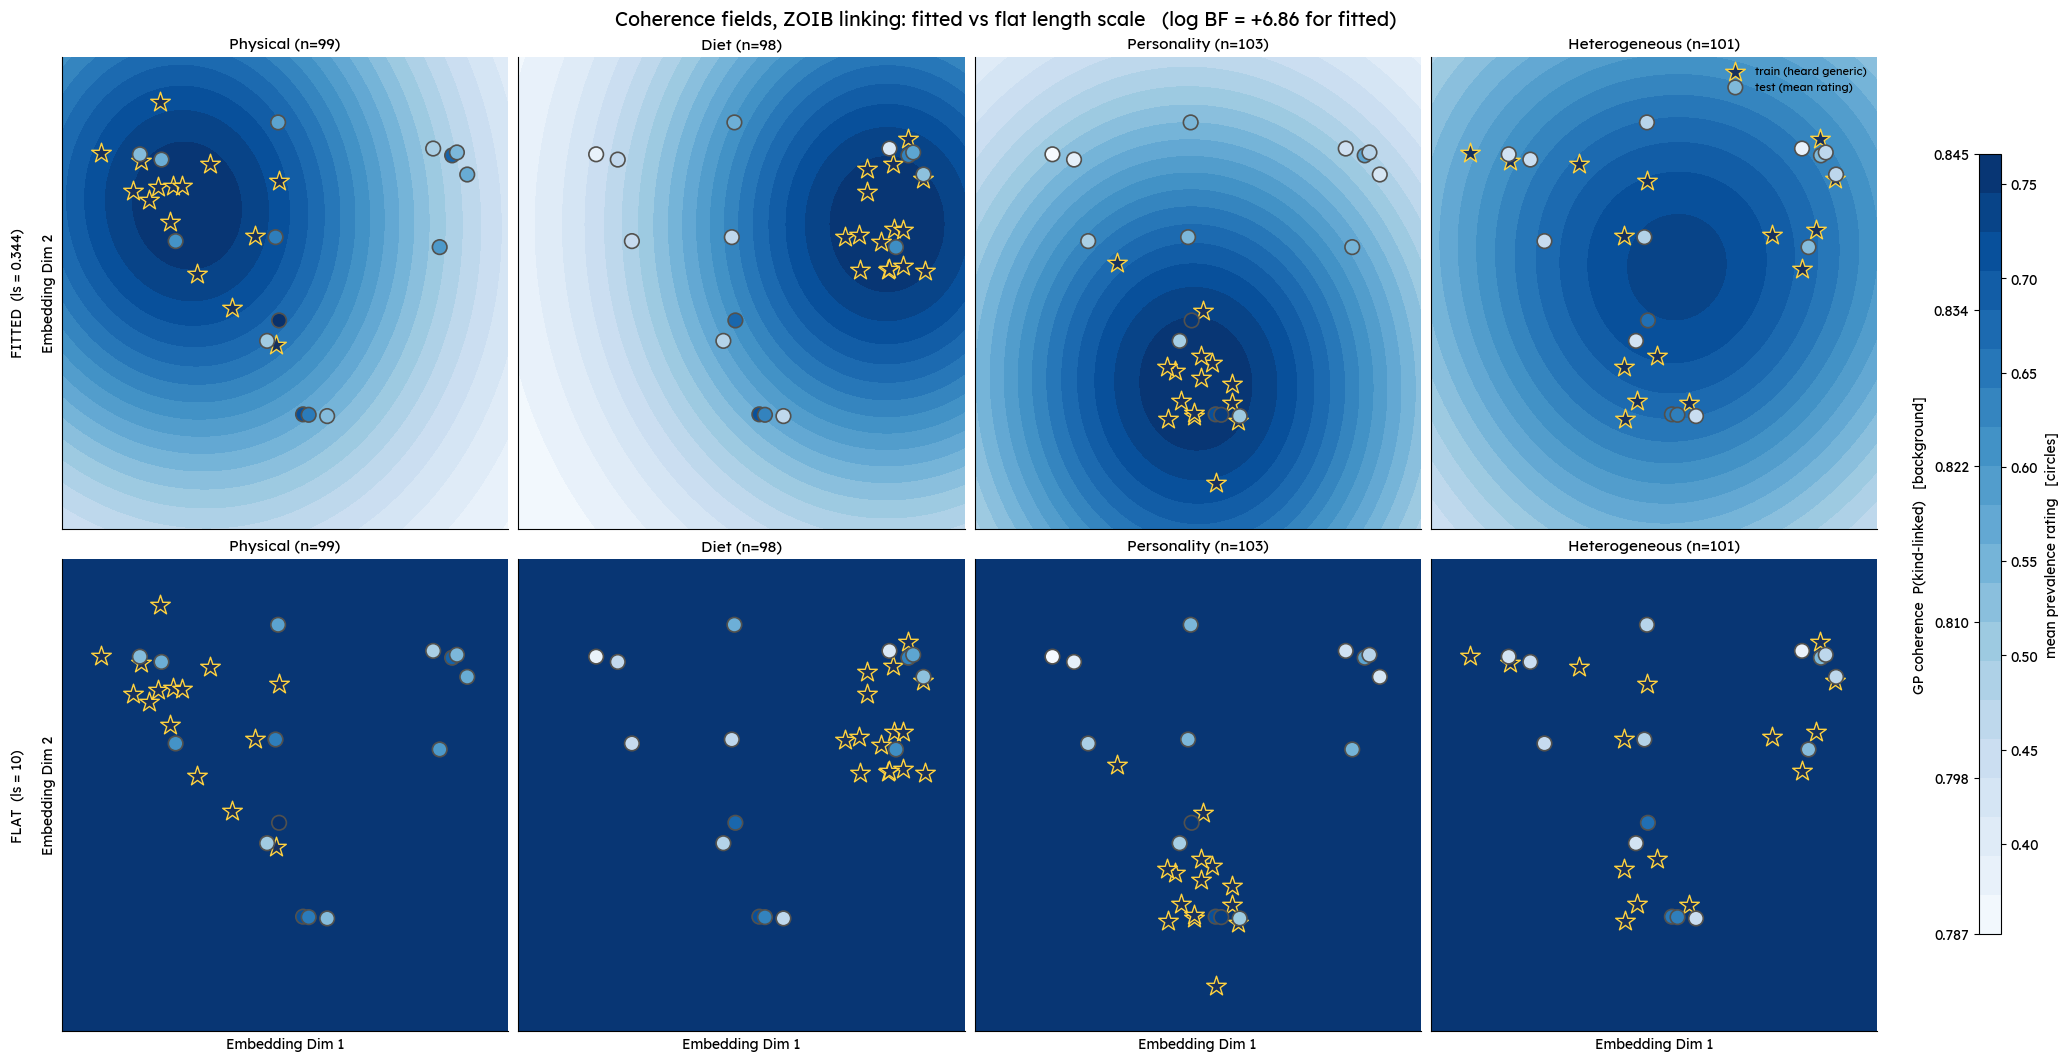

In [4]:
fig, axes = plt.subplots(len(MODELS), len(inf.CONDITIONS), figsize=(20, 10.5), layout='constrained')
for row, (name, m) in enumerate(MODELS.items()):
    for col, c in enumerate(inf.CONDITIONS):
        ax = axes[row, col]
        cs = ax.contourf(gx, gy, fields[name, c], levels=LEVELS, cmap=CMAP)
        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:, 0], x_tr[:, 1], s=220, marker='*', color='#16305e', edgecolor='#ffd23f', lw=1.0,
                   zorder=3, label='train (heard generic)')
        ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=110, c=emp_cond[c], cmap=CMAP, vmin=RAT_LO, vmax=RAT_HI,
                   edgecolor='#52514e', linewidth=1.2, zorder=4, label='test (mean rating)')
        ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{c.capitalize()} (n={N_cond[c]})", fontsize=11)
        if col == 0:
            ax.set_ylabel(f"{name.upper()}  (ls = {m['ls']:.3g})\n\nEmbedding Dim 2")
        if row == len(MODELS) - 1:
            ax.set_xlabel('Embedding Dim 1')
axes[0, -1].legend(fontsize=8, loc='upper right')

# one colorbar, two scales: coherence on the left, mean rating on the right
cb = fig.colorbar(cs, ax=axes, location='right', shrink=0.8, aspect=35, pad=0.02)
cb.set_ticks(np.linspace(COH_LO, COH_HI, 6), labels=[f'{v:.3f}' for v in np.linspace(COH_LO, COH_HI, 6)])
cb.ax.yaxis.set_ticks_position('left'); cb.ax.yaxis.set_label_position('left')
cb.set_label('GP coherence  P(kind-linked)   [background]')
cb_r = cb.ax.twinx()
cb_r.set_ylim(RAT_LO, RAT_HI)
cb_r.set_ylabel('mean prevalence rating   [circles]')
for s in cb_r.spines.values():
    s.set_visible(False)

fig.suptitle(f"Coherence fields, ZOIB linking: fitted vs flat length scale   "
             f"(log BF = {log_bf:+.2f} for fitted)", fontsize=14)
out_png = os.path.join(RESULTS, 'coherence-field-fig-shared-scale.png')
fig.savefig(out_png, dpi=150, bbox_inches='tight')
print('saved', out_png)
plt.show()

### 2b. Mean prevalence ratings alone (no coherence field)

The same circles as above (same colormap, same rating range, same axes), without the field behind them,
to see the pattern of mean ratings on its own. Stars are each condition's trained features.

saved results/study9-fit-zoib/test-prevalence-no-field.png


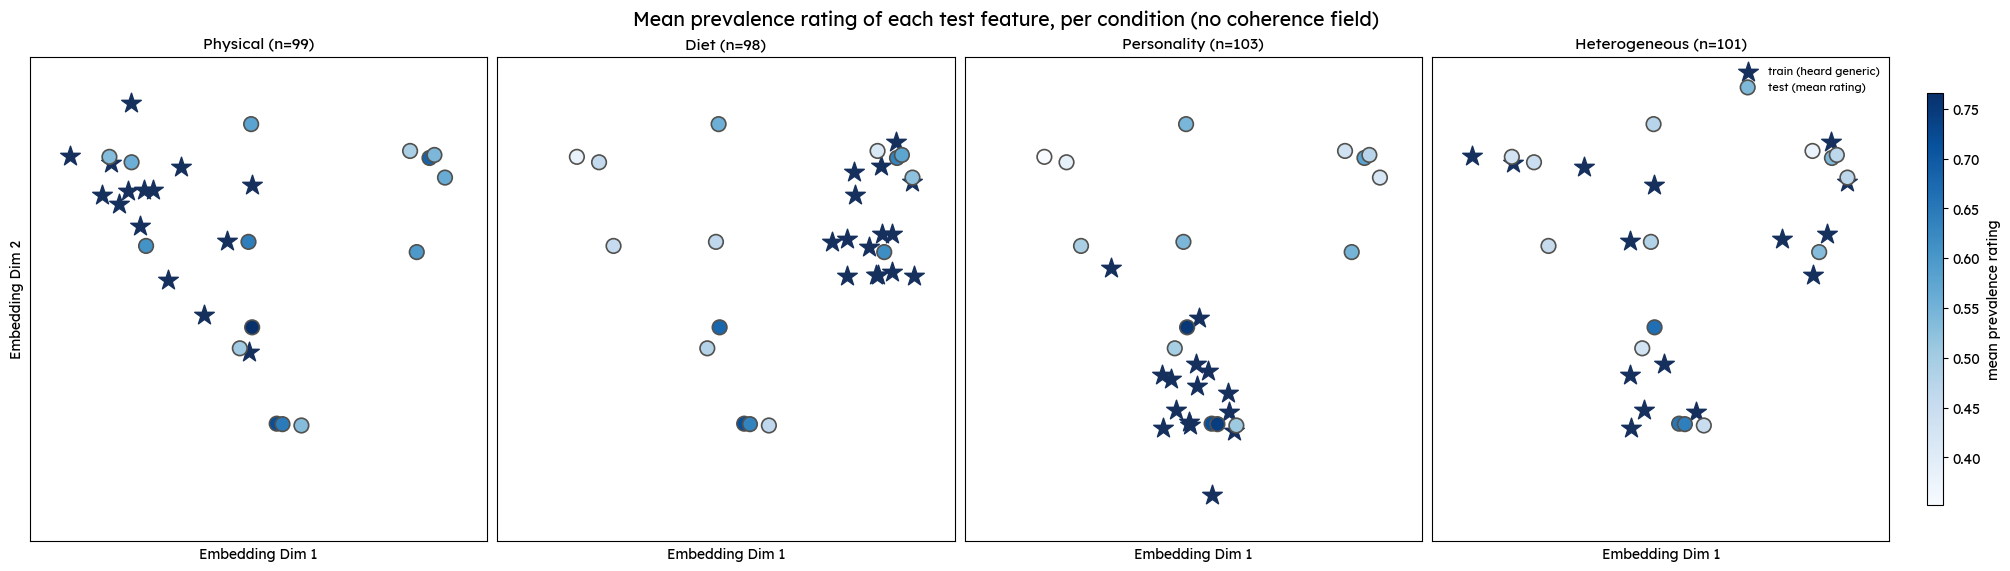

In [5]:
fig, axes = plt.subplots(1, len(inf.CONDITIONS), figsize=(20, 5.6), layout='constrained')
for ax, c in zip(axes, inf.CONDITIONS):
    x_tr = np.array(geom['x_train_cond'][c])
    ax.scatter(x_tr[:, 0], x_tr[:, 1], s=220, marker='*', color='#16305e', edgecolor='#16305e', lw=1.0,
               zorder=3, label='train (heard generic)')
    sc = ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=110, c=emp_cond[c], cmap=CMAP, vmin=RAT_LO, vmax=RAT_HI,
                    edgecolor='#52514e', linewidth=1.2, zorder=4, label='test (mean rating)')
    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True)
    ax.set_title(f"{c.capitalize()} (n={N_cond[c]})", fontsize=11)
    ax.set_xlabel('Embedding Dim 1')
axes[0].set_ylabel('Embedding Dim 2')
axes[-1].legend(fontsize=8, loc='upper right')
fig.colorbar(sc, ax=axes, location='right', shrink=0.85, aspect=25, pad=0.02,
             label='mean prevalence rating')
fig.suptitle('Mean prevalence rating of each test feature, per condition (no coherence field)', fontsize=14)
out_png = os.path.join(RESULTS, 'test-prevalence-no-field.png')
fig.savefig(out_png, dpi=150, bbox_inches='tight')
print('saved', out_png)
plt.show()

### 2c. One figure per fit, 2×2

The section 2 figure split into one 2×2 figure per model (one panel per condition). Everything else is the
same: the coherence range is shared across both models, test circles use the same colormap on the rating
range, and the colorbar shows coherence on the left and mean rating on the right. Saved to
`results/study9-fit-zoib/coherence-field-fig-shared-scale-<model>.png`.

saved results/study9-fit-zoib/coherence-field-fig-shared-scale-fitted.png


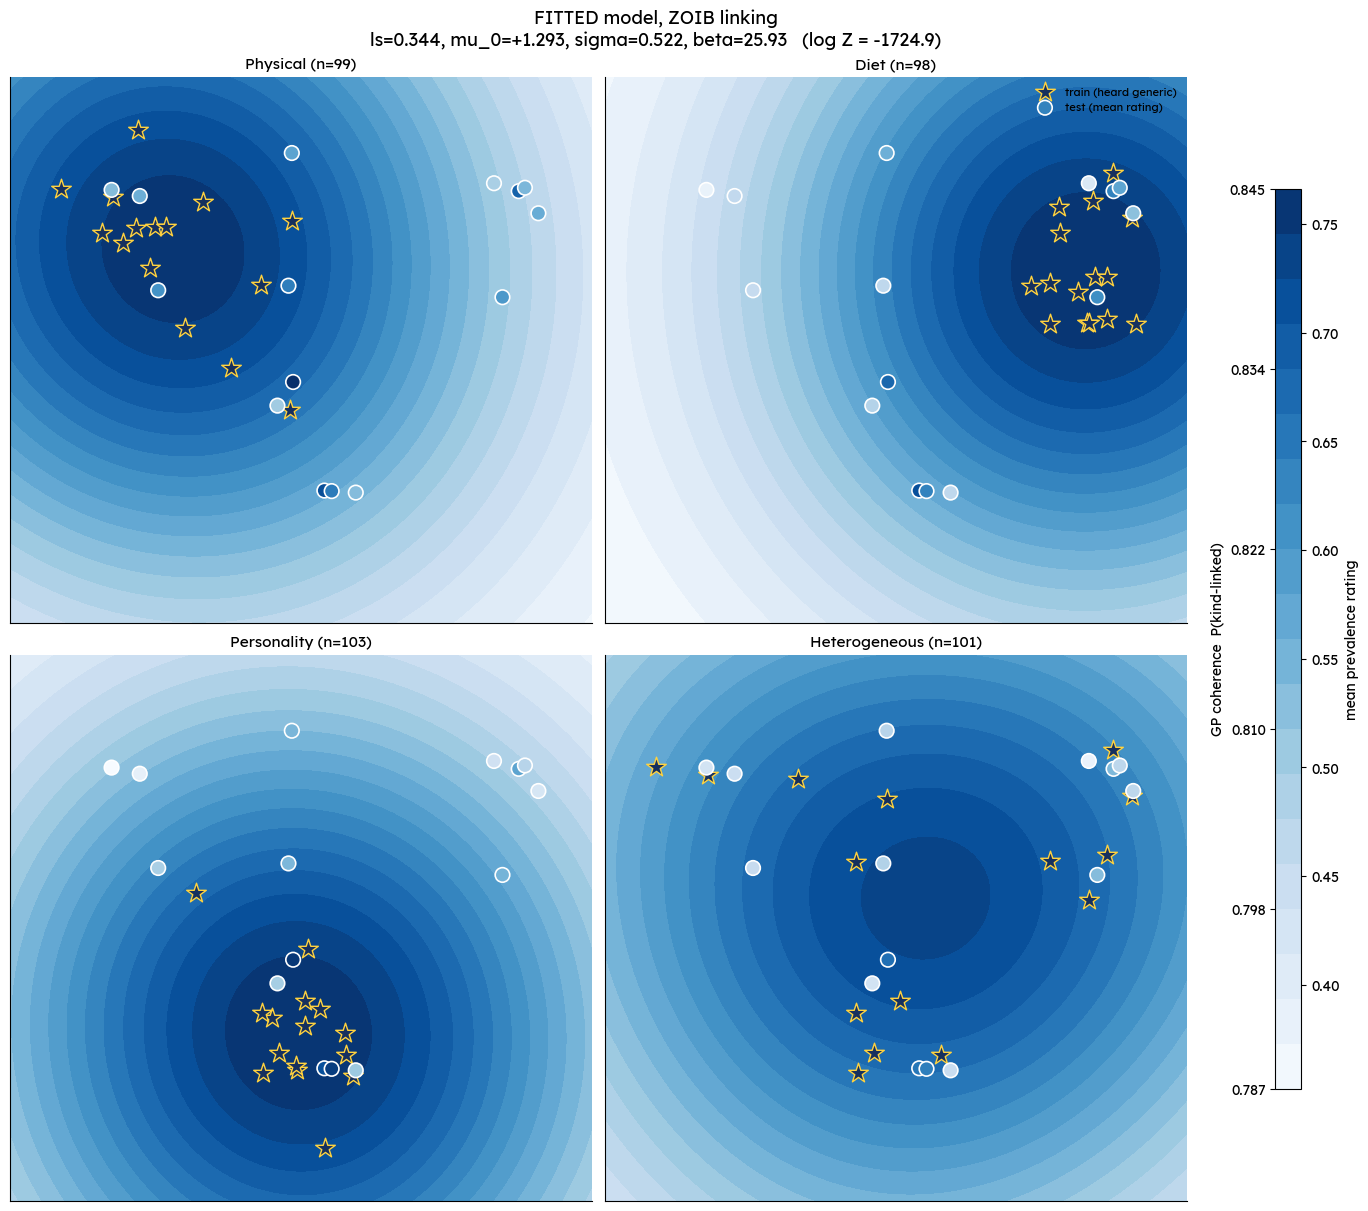

saved results/study9-fit-zoib/coherence-field-fig-shared-scale-flat.png


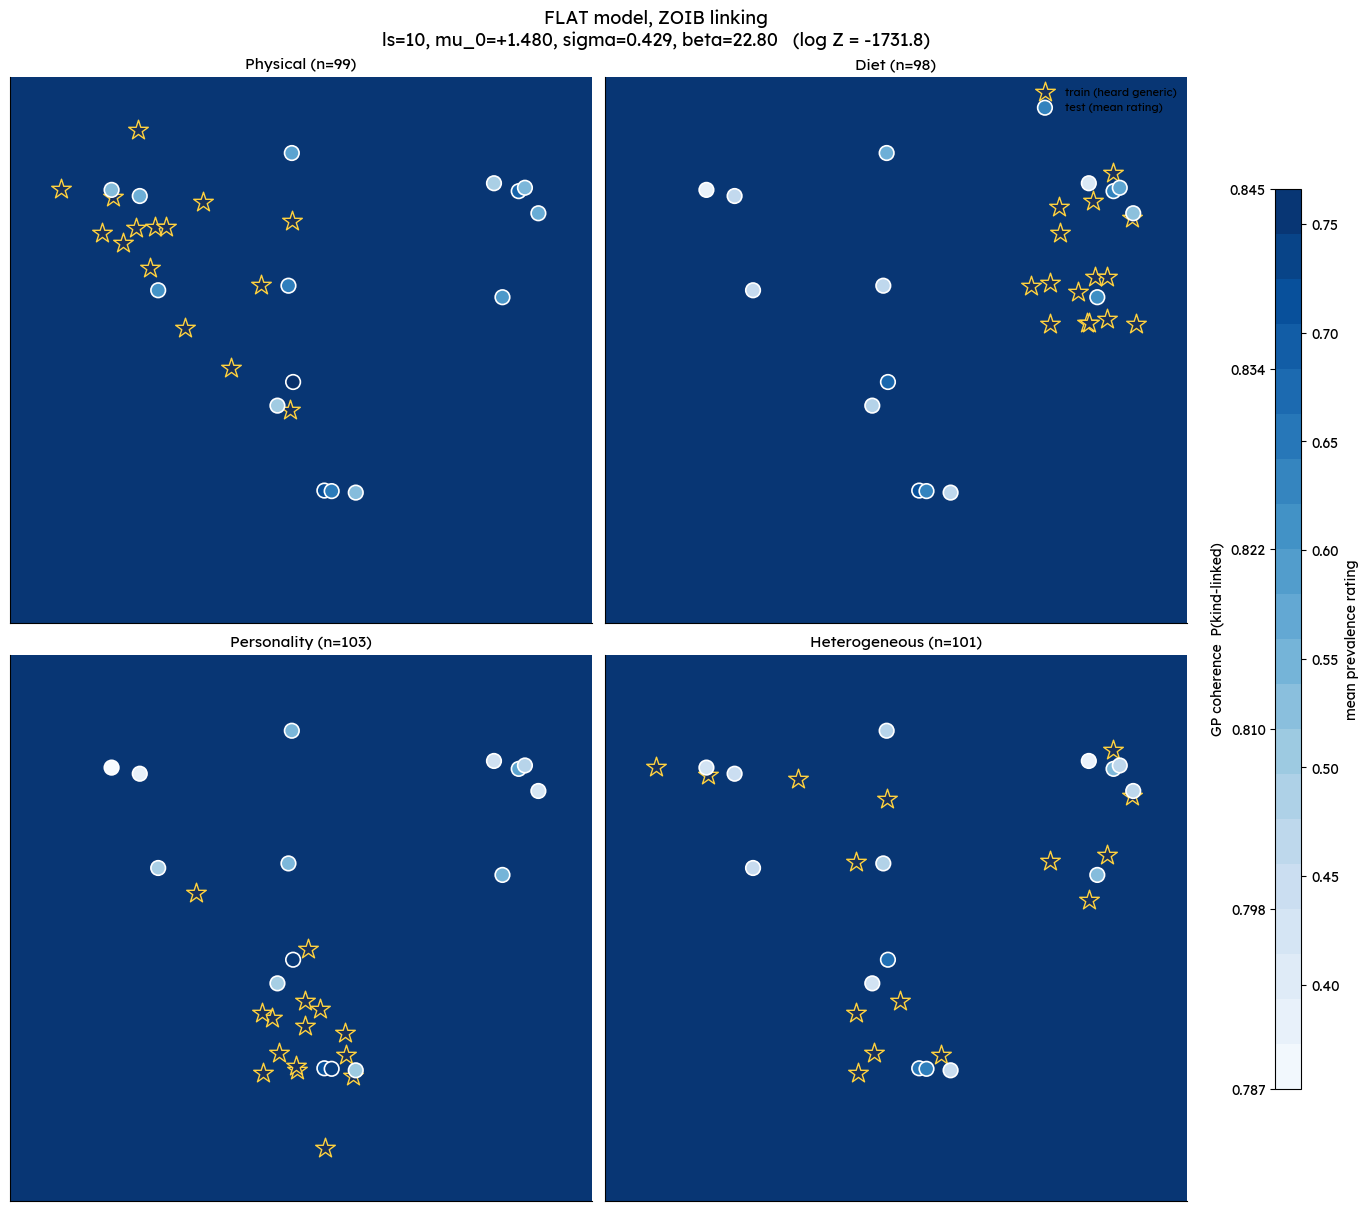

In [6]:
def plot_fit_square(name, m):
    fig, axes = plt.subplots(2, 2, figsize=(13, 12), layout='constrained')
    for ax, c in zip(axes.ravel(), inf.CONDITIONS):
        cs = ax.contourf(gx, gy, fields[name, c], levels=LEVELS, cmap=CMAP)
        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:, 0], x_tr[:, 1], s=220, marker='*', color='#16305e', edgecolor='#ffd23f', lw=1.0,
                   zorder=3, label='train (heard generic)')
        ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=110, c=emp_cond[c], cmap=CMAP, vmin=RAT_LO, vmax=RAT_HI,
                   edgecolor='#ffffff', linewidth=1.2, zorder=4, label='test (mean rating)')
        ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
        ax.set_xticks([]); ax.set_yticks([])
        # if np.ptp(field_at_test[name, c]) > 1e-3:
        #     r_txt = f"r(field, rating) = {np.corrcoef(field_at_test[name, c], emp_cond[c])[0, 1]:+.2f}"
        # else:
        #     r_txt = f"field constant ({field_at_test[name, c].mean():.3f})"
        ax.set_title(f"{c.capitalize()} (n={N_cond[c]})", fontsize=11)
        # ax.set_xlabel('Embedding Dim 1'); ax.set_ylabel('Embedding Dim 2')
    axes[0, 1].legend(fontsize=8, loc='upper right')

    cb = fig.colorbar(cs, ax=axes, location='right', shrink=0.8, aspect=35, pad=0.02)
    cb.set_ticks(np.linspace(COH_LO, COH_HI, 6), labels=[f'{v:.3f}' for v in np.linspace(COH_LO, COH_HI, 6)])
    cb.ax.yaxis.set_ticks_position('left'); cb.ax.yaxis.set_label_position('left')
    cb.set_label('GP coherence  P(kind-linked)')
    cb_r = cb.ax.twinx()
    cb_r.set_ylim(RAT_LO, RAT_HI)
    cb_r.set_ylabel('mean prevalence rating')
    for s in cb_r.spines.values():
        s.set_visible(False)

    fig.suptitle(f"{name.upper()} model, ZOIB linking\n"
                 f"ls={m['ls']:.3g}, mu_0={m['mu_0']:+.3f}, sigma={m['sigma']:.3f}, beta={m['beta']:.2f}   "
                 f"(log Z = {m['elbo']:.1f})", fontsize=13)
    out_png = os.path.join(RESULTS, f'coherence-field-fig-shared-scale-{name}.png')
    fig.savefig(out_png, dpi=150, bbox_inches='tight')
    print('saved', out_png)
    plt.show()

for name, m in MODELS.items():
    plot_fit_square(name, m)

In [7]:
# standalone train / test legend for slides, with and without the star's yellow edge
from matplotlib.lines import Line2D

def save_legend(star_edge, suffix=''):
    handles = [
        Line2D([], [], ls='none', marker='*', markersize=20, markerfacecolor='#16305e',
               markeredgecolor=star_edge, markeredgewidth=1.0, label='training feature (heard generic)'),
        Line2D([], [], ls='none', marker='o', markersize=12, markerfacecolor=plt.get_cmap(CMAP)(0.55),
               markeredgecolor='#52514e', markeredgewidth=1.2, label='test feature (color = mean prevalence rating)'),
    ]
    fig = plt.figure(figsize=(5.5, 1.2))
    fig.legend(handles=handles, loc='center', frameon=False, fontsize=13, handletextpad=0.6, labelspacing=0.9)
    for ext in ('png', 'pdf'):
        out = os.path.join(RESULTS, f'legend-train-test{suffix}.{ext}')
        fig.savefig(out, dpi=200, bbox_inches='tight', transparent=True)
        print('saved', out)
    plt.show()

save_legend('#ffd23f')                          # yellow-edged star, as on the field plots
save_legend('#16305e', suffix='-no-star-edge')  # plain navy star

saved results/study9-fit-zoib/legend-train-test.png


saved results/study9-fit-zoib/legend-train-test.pdf


<Figure size 550x120 with 0 Axes>

saved results/study9-fit-zoib/legend-train-test-no-star-edge.png
saved results/study9-fit-zoib/legend-train-test-no-star-edge.pdf


<Figure size 550x120 with 0 Axes>